# ПР-2. Разведочный анализ данных (EDA)
**Проект:** CryptoMind AI — интеллектуальный анализ крипторынка
**Выполнил:** &lt;Баргыбаев Нуртилек, группа cs32&gt;

## План анализа (приоритеты)
1. Инженерия признаков: доходности, волатильность дня (дальше — все выводы опираются на них)
2. Качество данных: пропуски, выбросы
3. Три гипотезы со статистическими тестами
4. Источники утечки данных
5. Приоритетные ML-задачи и оценка значимости признаков

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
df = pd.read_csv("../data/processed/crypto_daily.csv")
df.head(3)

,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_base_volume,taker_buy_quote_volume,symbol,date
0,1502928000000,4261.4800,4485.3900,4200.7400,4285.0800,795.1504,3454770.0507,3427,616.2485,2678216.4006,BTCUSDT,2017-08-17
1,1503014400000,4285.0800,4371.5200,3938.7700,4108.3700,1199.8883,5086958.3062,5233,972.8687,4129123.3165,BTCUSDT,2017-08-18
2,1503100800000,4108.3700,4184.6900,3850.0000,4139.9800,381.3098,1549483.7354,2153,274.3360,1118001.8701,BTCUSDT,2017-08-19


## 1. Инженерия признаков: доходности
Цены разных монет сравнивать напрямую бессмысленно (у BTC ~100 000, у SOL ~200).
Рабочая величина в финансах — **логарифмическая доходность**:
r_t = ln(close_t / close_{t-1}). Она симметрична (+10% и −10% дают ±0.095)
и аддитивна во времени — удобна для статистики.
Добавим также **диапазон дня** (high−low)/close в % — простейшую меру внутридневной волатильности.

In [2]:
df = df.sort_values(["symbol", "open_time"]).reset_index(drop=True)

df["ret"] = df.groupby("symbol")["close"].pct_change()          # простая доходность
df["log_ret"] = np.log(df["close"] / df.groupby("symbol")["close"].shift(1))
df["range_pct"] = (df["high"] - df["low"]) / df["close"] * 100  # волатильность дня, %

df.head(5)

,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_base_volume,taker_buy_quote_volume,symbol,date,ret,log_ret,range_pct
0,1502928000000,4261.4800,4485.3900,4200.7400,4285.0800,795.1504,3454770.0507,3427,616.2485,2678216.4006,BTCUSDT,2017-08-17,NaN,NaN,6.6428
1,1503014400000,4285.0800,4371.5200,3938.7700,4108.3700,1199.8883,5086958.3062,5233,972.8687,4129123.3165,BTCUSDT,2017-08-18,-0.0412,-0.0421,10.5334
2,1503100800000,4108.3700,4184.6900,3850.0000,4139.9800,381.3098,1549483.7354,2153,274.3360,1118001.8701,BTCUSDT,2017-08-19,0.0077,0.0077,8.0843
3,1503187200000,4120.9800,4211.0800,4032.6200,4086.2900,467.0830,1930364.3903,2321,376.7959,1557401.3337,BTCUSDT,2017-08-20,-0.0130,-0.0131,4.3673
4,1503273600000,4069.1300,4119.6200,3911.7900,4016.0000,691.7431,2797231.7140,3972,557.3561,2255662.5532,BTCUSDT,2017-08-21,-0.0172,-0.0174,5.1750


In [3]:
print("Пропуски по колонкам:")
print(df.isna().sum())

print("\nСтатистика доходности по монетам:")
df.groupby("symbol")["log_ret"].describe().T

Пропуски по колонкам:
open_time                 0
open                      0
high                      0
low                       0
close                     0
volume                    0
quote_volume              0
trades                    0
taker_buy_base_volume     0
taker_buy_quote_volume    0
symbol                    0
date                      0
ret                       3
log_ret                   3
range_pct                 0
dtype: int64

Статистика доходности по монетам:


symbol,BTCUSDT,ETHUSDT,SOLUSDT
count,3344.0000,3344.0000,2254.0000
mean,0.0009,0.0006,0.0015
std,0.0353,0.0456,0.0593
min,-0.5026,-0.5905,-0.5490
25%,-0.0138,-0.0194,-0.0287
50%,0.0006,0.0007,-0.0003
75%,0.0154,0.0211,0.0296
max,0.2030,0.2338,0.3776


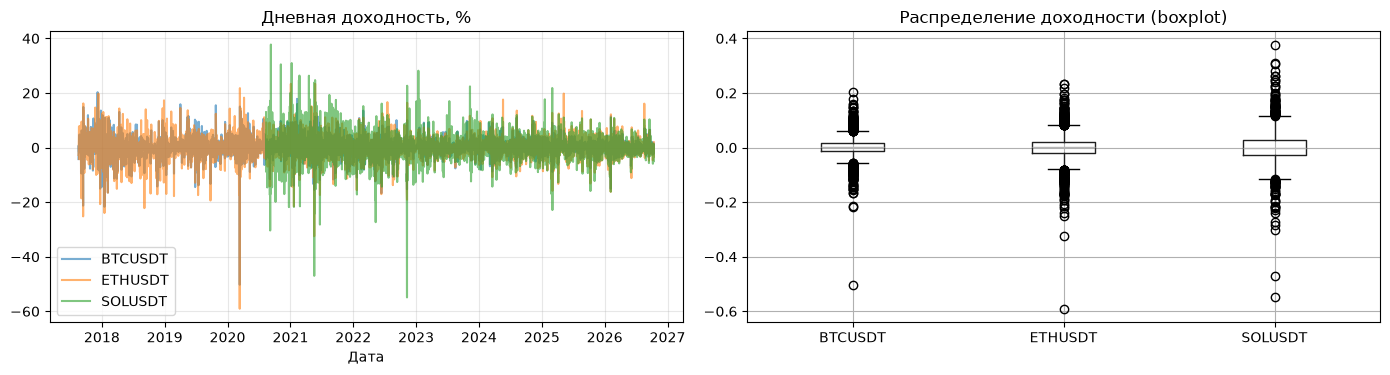

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for sym in ["BTCUSDT", "ETHUSDT", "SOLUSDT"]:
    d = df[df["symbol"] == sym]
    axes[0].plot(pd.to_datetime(d["date"]), d["log_ret"] * 100, label=sym, alpha=0.6)
axes[0].set_title("Дневная доходность, %")
axes[0].set_xlabel("Дата"); axes[0].legend(); axes[0].grid(alpha=0.3)

df.boxplot(column="log_ret", by="symbol", ax=axes[1])
axes[1].set_title("Распределение доходности (boxplot)")
axes[1].set_xlabel(""); plt.suptitle("")
plt.tight_layout(); plt.show()

## 2. Качество данных: выводы
(заполни по факту, ориентиры:)
- Пропуски в ret/log_ret: по 1 на каждую монету — это первый день ряда, расчёт
  доходности невозможен. Оставляем и обрабатываем в ПР-3.
- Распределение доходности: среднее около нуля, но хвосты тяжёлые — видны дни
  с |r| > 20% (выбросы). Видно на boxplot: точки за пределами усов.
- Волатильность SOL > ETH > BTC — младшие монеты рискованнее.

## 3. Статистические гипотезы

### Гипотеза 1. Средняя дневная доходность BTC равна нулю
H0: среднее log_ret = 0, H1: ≠ 0.
Тест: одновыборочный t-тест.
Обоснование выбора: выборка большая (n ≈ 3300), по ЦПТ среднее приближается
к нормальному даже при тяжёлых хвостах; сравниваем среднее одной выборки с константой.

In [5]:
from scipy import stats

btc = df[df["symbol"] == "BTCUSDT"]["log_ret"].dropna()
t_stat, p_val = stats.ttest_1samp(btc, 0)

print(f"n = {len(btc)}")
print(f"средняя доходность: {btc.mean() * 100:.4f}% в день")
print(f"t = {t_stat:.3f}, p = {p_val:.4f}")
print("H0 отвергаем" if p_val < 0.05 else "H0 не отвергаем")

n = 3344
средняя доходность: 0.0887% в день
t = 1.453, p = 0.1463
H0 не отвергаем


### Гипотеза 2. Доходности BTC и ETH синхронны (корреляция ≠ 0)
H0: корреляция Пирсона = 0.
Тест: pearsonr. Обоснование: обе переменные количественные, связь ожидается
линейной, n велико. Дополнительно считаем Спирмена как проверку устойчивости
к выбросам (хвосты у доходностей тяжёлые).

In [6]:
wide = df.pivot(index="date", columns="symbol", values="log_ret").dropna()

r, p1 = stats.pearsonr(wide["BTCUSDT"], wide["ETHUSDT"])
rs, p2 = stats.spearmanr(wide["BTCUSDT"], wide["ETHUSDT"])
print(f"Пирсон:  r = {r:.3f}, p = {p1:.2e}")
print(f"Спирмен: r = {rs:.3f}, p = {p2:.2e}")

Пирсон:  r = 0.815, p = 0.00e+00
Спирмен: r = 0.810, p = 0.00e+00


### Гипотеза 3. День недели связан с направлением доходности BTC
H0: день недели и знак доходности независимы.
Тест: χ² Пирсона по таблице сопряжённости.
Обоснование: обе переменные категориальные — прямое назначение χ².
Крипторынок работает 24/7, биржевой «эффект выходных» может отсутствовать — проверим.

In [7]:
b = df[df["symbol"] == "BTCUSDT"].copy()
b["dow"] = pd.to_datetime(b["date"]).dt.day_name()
b["sign"] = np.where(b["log_ret"] > 0, "рост",
            np.where(b["log_ret"] < 0, "падение", "без изм."))

tab = pd.crosstab(b["dow"], b["sign"])
chi2, p, dof, exp = stats.chi2_contingency(tab)
print(tab)
print(f"\nχ² = {chi2:.2f}, степеней свободы = {dof}, p = {p:.4f}")
print("H0 отвергаем" if p < 0.05 else "H0 не отвергаем")

sign       без изм.  падение  рост
dow                               
Friday            0      228   250
Monday            0      235   243
Saturday          0      211   267
Sunday            0      231   247
Thursday          1      257   220
Tuesday           0      244   234
Wednesday         0      227   250

χ² = 16.61, степеней свободы = 12, p = 0.1649
H0 не отвергаем


### Выводы по гипотезам
- **H1:** p = <вставь>. Средняя доходность <равна/не равна> нулю... (подсказка:
  даже если p маленькое, посмотри на величину среднего — статистическая
  значимость ≠ экономическая. +0.05% в день — это много или мало за год?)
- **H2:** корреляция <вставь> — рынки двигаются <синхронно/независимо>...
- **H3:** p = <вставь>. Эффекта дня недели <есть/нет>...

## 4. Источники утечки данных (data leakage)

1. **Одновременные признаки.** Чтобы предсказать доходность дня t, нельзя
   использовать close/volume дня t — они известны только в конце дня, и целевая
   переменная частично «встроена» в них. Правило: признаки из дней ≤ t−1,
   цель — день t.
2. **Скейлер/импьютер, обученный на всей выборке.** Если нормализовать данные
   до разбиения на train/test, в обучение просачивается информация из теста
   (среднее/дисперсия всего ряда). Лечение: весь препроцессинг — внутри
   Pipeline, fit только на train (сделаем в ПР-3).
3. **Пересекающиеся окна.** Rolling-признаки с окном k на стыке train/test
   используют данные из соседней выборки — окна надо строить внутри каждой части.
4. **Смещение выжившего.** В выборке только три крупные монеты, дожившие до
   2026 года. Выводы модели не распространяются на мелкие токены (большинство
   «умерших» монет в выборке не представлены).

## 5. Приоритетные ML-задачи и оценка значимости признаков

**Приоритет 1 (ПР-4, регрессия):** предсказать log_ret дня t по признакам дня t−1
(цена, объём, волатильность). Ожидание: R² будет низким — дневная доходность
близка к случайному блужданию (подтверждено H1), это честный результат.

**Приоритет 2 (ПР-5, классификация):** предсказать «сильное падение»
(ret ≤ −5%) — таких дней меньше ~10%, дисбаланс под требования работы.

**Предварительная оценка значимых признаков:**
- `range_pct` (волатильность) — самый перспективный: волатильность
  кластеризуется, падения сопровождаются расширением диапазона;
- `quote_volume` и `volume` — всплески объёма сопровождают крупные движения;
- `ret` предыдущего дня — слабый моментум (проверим в ПР-7);
- `trades` — ожидаемо дублирует объём (сильно коррелирован), пользы мало.

### Выводы по гипотезам
- **H1 (средняя доходность BTC = 0):** p = 0.146 → H0 не отвергаем. Среднее
  +0.089%/день статистически неотличимо от нуля: волатильность (~3.6%/день)
  на порядок больше среднего. Вывод: дневная доходность близка к случайному
  блужданию — предсказывать её будет трудно (учтём в ПР-4).
- **H2 (корреляция BTC–ETH):** r = 0.815, p ≈ 0 → синхронность сильная,
  оба теста (Пирсон/Спирмен) согласны, выбросы на результат не влияют.
- **H3 (день недели):** χ² = 16.6, p = 0.165 → связи нет. Подтверждено:
  круглосуточный рынок не имеет «эффекта выходных».